# Day-ahead electricity price forecasting – Spain

Hourly Spanish market data 2015–2018 (ENTSO-E load/generation + day-ahead price) joined with
weather for Madrid. I forecast the next hour's price from the last 24 hours and compare
three things:

1. persistence (price stays the same) – the baseline
2. a stacked LSTM
3. a small 1D-CNN

Done as a university group project (Group C) during my M.Sc. in Smart Energy Systems.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

## Data

In [2]:
energy = pd.read_csv("energy_dataset.csv", parse_dates=["time"])
weather = pd.read_csv("weather_features.csv", parse_dates=["dt_iso"])

energy["time"] = pd.to_datetime(energy["time"], utc=True)
weather["dt_iso"] = pd.to_datetime(weather["dt_iso"], utc=True)
energy = energy.set_index("time")

# weather has 5 cities and some duplicated hours; I only use Madrid
weather["city_name"] = weather["city_name"].str.strip()
madrid = (weather[weather["city_name"] == "Madrid"]
          .set_index("dt_iso")[["temp", "pressure", "humidity", "wind_speed", "clouds_all"]]
          .resample("h").mean())

df = energy.join(madrid, how="inner")
print(df.shape, df.index.min(), "->", df.index.max())

(35064, 33) 2014-12-31 23:00:00+00:00 -> 2018-12-31 22:00:00+00:00


In [3]:
target = "price actual"
cols = [target, "total load actual", "generation wind onshore", "generation solar",
        "temp", "humidity", "wind_speed"]

df = df[cols].interpolate(limit=3).dropna()

hours = df.index.hour
df["hour_sin"] = np.sin(2 * np.pi * hours / 24)
df["hour_cos"] = np.cos(2 * np.pi * hours / 24)
df["is_weekend"] = (df.index.dayofweek >= 5).astype(int)

feature_cols = list(df.columns)  # price is column 0
df.describe().T

C:\Users\advai\AppData\Local\Temp\ipykernel_10976\1778226088.py:10: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["is_weekend"] = (df.index.dayofweek >= 5).astype(int)


,count,mean,std,min,25%,50%,75%,max
price actual,35056.0,57.885385,14.200984,9.330,49.350000,5.802000e+01,68.010000,116.80
total load actual,35056.0,28698.128228,4575.655141,18041.000,24807.750000,2.890150e+04,32194.000000,41015.00
generation wind onshore,35056.0,5465.302811,3213.562982,0.000,2933.750000,4.850000e+03,7399.000000,17436.00
generation solar,35056.0,1432.656091,1680.011933,0.000,71.000000,6.160000e+02,2578.000000,5792.00
temp,35056.0,288.278778,9.327378,264.132,281.150000,2.869400e+02,294.952500,313.33
humidity,35056.0,58.724526,24.885851,0.000,38.000000,5.900000e+01,81.000000,100.00
wind_speed,35056.0,2.433307,1.972512,0.000,1.000000,2.000000e+00,3.000000,18.00
hour_sin,35056.0,0.000174,0.707098,-1.000,-0.707107,1.224647e-16,0.707107,1.00
hour_cos,35056.0,0.000126,0.707136,-1.000,-0.707107,6.123234e-17,0.707107,1.00
is_weekend,35056.0,0.286028,0.451909,0.000,0.000000,0.000000e+00,1.000000,1.00


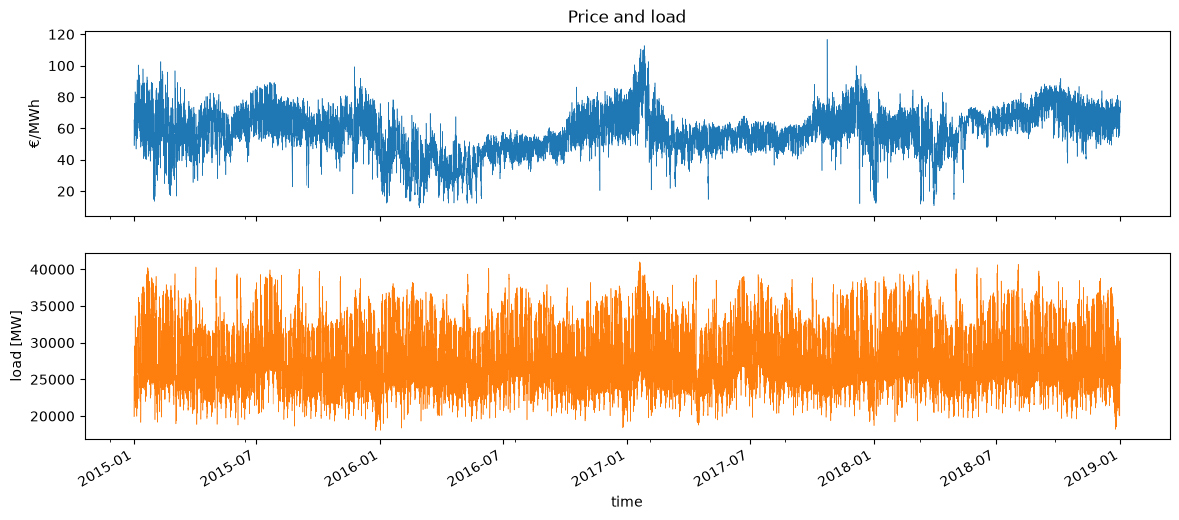

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
df[target].plot(ax=ax[0], lw=0.4); ax[0].set_ylabel("€/MWh")
df["total load actual"].plot(ax=ax[1], lw=0.4, color="tab:orange"); ax[1].set_ylabel("load [MW]")
ax[0].set_title("Price and load")
plt.show()

In [5]:
# how price relates to the main drivers
df[[target, "total load actual", "generation wind onshore", "generation solar"]].corr()[target]

price actual               1.000000
total load actual          0.435793
generation wind onshore   -0.220907
generation solar           0.098625
Name: price actual, dtype: float64

## Split + scaling

Chronological 70 / 15 / 15. Scaler fitted on train only.

In [6]:
n = len(df)
train_end, val_end = int(n * 0.70), int(n * 0.85)

scaler = MinMaxScaler().fit(df.iloc[:train_end])
scaled = scaler.transform(df)
p_min, p_max = scaler.data_min_[0], scaler.data_max_[0]
to_eur = lambda x: np.asarray(x).ravel() * (p_max - p_min) + p_min

LOOKBACK = 24

def make_windows(data, start, end, lookback=LOOKBACK):
    idx = range(max(start, lookback), end)
    X = np.stack([data[t - lookback:t] for t in idx])
    y = data[list(idx), 0]
    return X, y

X_train, y_train = make_windows(scaled, 0, train_end)
X_val, y_val = make_windows(scaled, train_end, val_end)
X_test, y_test = make_windows(scaled, val_end, n)
print(X_train.shape, X_val.shape, X_test.shape)

(24515, 24, 10) (5258, 24, 10) (5259, 24, 10)


## Models

In [7]:
n_feat = X_train.shape[2]
early_stop = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

lstm = keras.Sequential([
    layers.Input(shape=(LOOKBACK, n_feat)),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dense(1),
])
lstm.compile(optimizer="adam", loss="mse")
lstm_hist = lstm.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=40, batch_size=64, callbacks=[early_stop], verbose=2)

Epoch 1/40


384/384 - 21s - 53ms/step - loss: 0.0083 - val_loss: 0.0052


Epoch 2/40


384/384 - 15s - 39ms/step - loss: 0.0028 - val_loss: 0.0040


Epoch 3/40


384/384 - 15s - 39ms/step - loss: 0.0023 - val_loss: 0.0035


... (30 outputs left out)

Epoch 19/40


384/384 - 13s - 34ms/step - loss: 6.9584e-04 - val_loss: 9.4744e-04


Epoch 20/40


384/384 - 15s - 39ms/step - loss: 6.8496e-04 - val_loss: 8.9842e-04


In [8]:
cnn = keras.Sequential([
    layers.Input(shape=(LOOKBACK, n_feat)),
    layers.Conv1D(32, kernel_size=3, activation="relu"),
    layers.Conv1D(32, kernel_size=3, activation="relu"),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),
])
cnn.compile(optimizer="adam", loss="mse")
cnn_hist = cnn.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=40, batch_size=64, callbacks=[early_stop], verbose=2)

Epoch 1/40


384/384 - 5s - 13ms/step - loss: 0.0095 - val_loss: 0.0099


Epoch 2/40


384/384 - 2s - 4ms/step - loss: 0.0045 - val_loss: 0.0066


Epoch 3/40


384/384 - 3s - 7ms/step - loss: 0.0036 - val_loss: 0.0055


... (70 outputs left out)

Epoch 39/40


384/384 - 3s - 8ms/step - loss: 0.0012 - val_loss: 0.0020


Epoch 40/40


384/384 - 3s - 8ms/step - loss: 0.0011 - val_loss: 0.0020


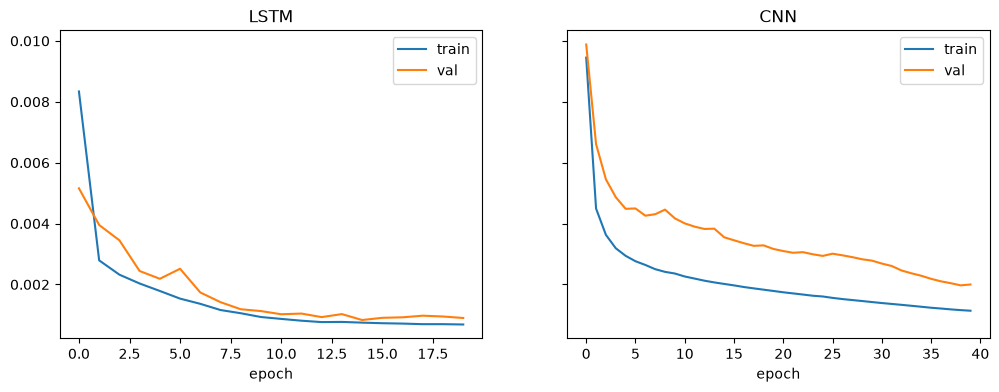

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, h, name in zip(ax, [lstm_hist, cnn_hist], ["LSTM", "CNN"]):
    a.plot(h.history["loss"], label="train")
    a.plot(h.history["val_loss"], label="val")
    a.set_title(name); a.set_xlabel("epoch"); a.legend()
plt.show()

## Results on the test period

In [10]:
y_true = to_eur(y_test)
preds = {
    "Persistence": to_eur(X_test[:, -1, 0]),
    "LSTM": to_eur(lstm.predict(X_test, verbose=0)),
    "1D-CNN": to_eur(cnn.predict(X_test, verbose=0)),
}

results = pd.DataFrame({
    name: {"MAE [€/MWh]": mean_absolute_error(y_true, p),
           "RMSE [€/MWh]": np.sqrt(mean_squared_error(y_true, p))}
    for name, p in preds.items()
}).T.round(2)
results

,MAE [€/MWh],RMSE [€/MWh]
Persistence,1.97,2.88
LSTM,1.72,2.28
1D-CNN,2.75,3.52


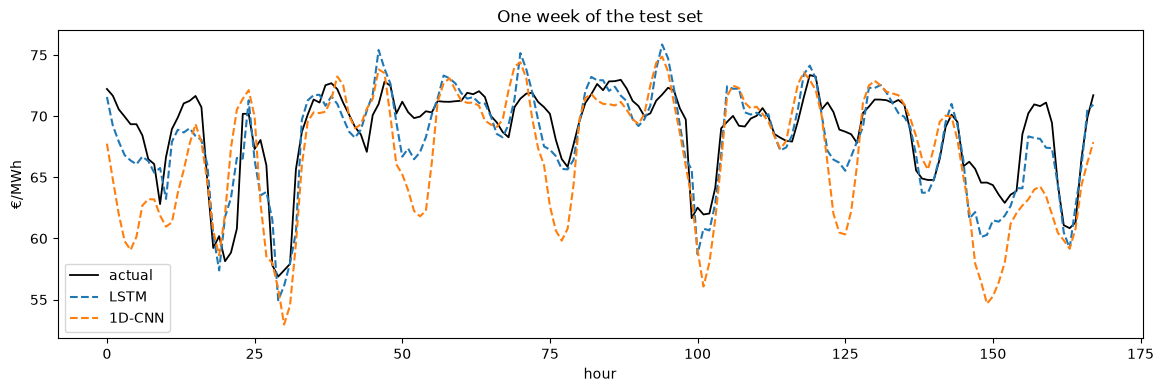

In [11]:
week = slice(0, 24 * 7)
plt.figure(figsize=(14, 4))
plt.plot(y_true[week], color="black", lw=1.3, label="actual")
for name in ["LSTM", "1D-CNN"]:
    plt.plot(preds[name][week], ls="--", label=name)
plt.ylabel("€/MWh"); plt.xlabel("hour")
plt.title("One week of the test set")
plt.legend()
plt.show()

## Takeaways

- Price is very autocorrelated hour to hour, so persistence is already decent – the networks
  have to beat that to be useful.
- Load and wind generation carry most of the extra signal (high wind → lower price, merit-order effect).
- Next steps: forecast all 24 hours of the next day at once (that's what a trader actually needs),
  and add gas/CO₂ prices which drive the marginal plant cost.